# 1. Data Loading and Initial Inspection

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import missingno as msno
import warnings
warnings.filterwarnings('ignore')

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

print("--- First 5 rows of the dataset ---")
display(df.head())

print("--- Dataset Shape (BEFORE) ---")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")

print("--- Dataset Info (BEFORE) ---")
df.info()

print("--- Statistical Summary (Numeric Features) ---")
display(df.describe())

--- First 5 rows of the dataset ---


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


--- Dataset Shape (BEFORE) ---
Rows: 7043, Columns: 21
--- Dataset Info (BEFORE) ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Cont

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


--- Missing Values Count (Initial) ---
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


<Figure size 1000x500 with 0 Axes>

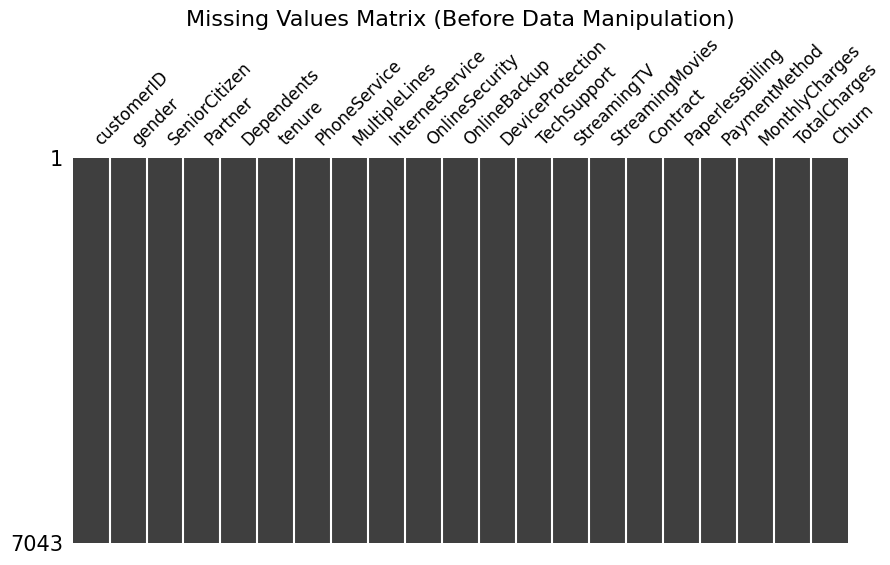

In [ ]:

print("--- Missing Values Count (Initial) ---")
print(df.isnull().sum())

plt.figure(figsize=(10, 5))
msno.matrix(df, figsize=(10,5), sparkline=False, fontsize=12)
plt.title("Missing Values Matrix (Before Data Manipulation)", fontsize=16)
plt.show()

-> 'customerID' column successfully dropped.
-> 'TotalCharges' successfully converted to numeric (float64).
-> Hidden missing values revealed in 'TotalCharges': 11


<Figure size 1000x500 with 0 Axes>

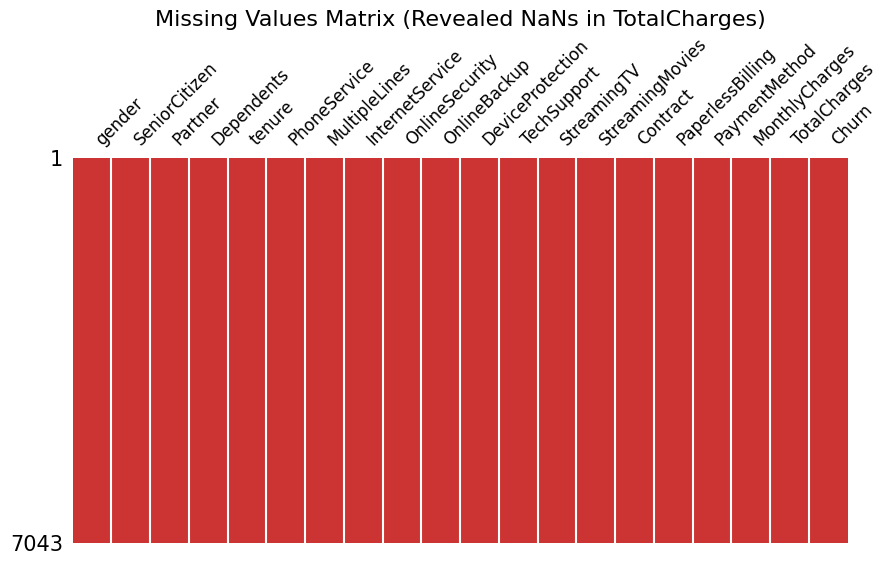

-> Dropped {hidden_nans} rows containing NaN values.
--- Dataset Shape (AFTER) ---
Rows: 7032, Columns: 20
Difference: Removed 11 rows and 1 column(s).
--- Dataset Info (AFTER) ---
<class 'pandas.core.frame.DataFrame'>
Index: 7032 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7032 non-null   object 
 1   SeniorCitizen     7032 non-null   int64  
 2   Partner           7032 non-null   object 
 3   Dependents        7032 non-null   object 
 4   tenure            7032 non-null   int64  
 5   PhoneService      7032 non-null   object 
 6   MultipleLines     7032 non-null   object 
 7   InternetService   7032 non-null   object 
 8   OnlineSecurity    7032 non-null   object 
 9   OnlineBackup      7032 non-null   object 
 10  DeviceProtection  7032 non-null   object 
 11  TechSupport       7032 non-null   object 
 12  StreamingTV       7032 non-null   object 
 13  Streami

In [ ]:

df_cleaned = df.copy()

if 'customerID' in df_cleaned.columns:
    df_cleaned.drop('customerID', axis=1, inplace=True)
    print("-> 'customerID' column successfully dropped.")

df_cleaned['TotalCharges'] = pd.to_numeric(df_cleaned['TotalCharges'], errors='coerce')
print("-> 'TotalCharges' successfully converted to numeric (float64).")

hidden_nans = df_cleaned['TotalCharges'].isnull().sum()
print(f"-> Hidden missing values revealed in 'TotalCharges': {hidden_nans}")

plt.figure(figsize=(10, 5))
msno.matrix(df_cleaned, figsize=(10,5), sparkline=False, fontsize=12, color=(0.8, 0.2, 0.2))
plt.title(f"Missing Values Matrix (Revealed NaNs in TotalCharges)", fontsize=16)
plt.show()

df_cleaned.dropna(inplace=True)
print("-> Dropped {hidden_nans} rows containing NaN values.")

print("=======================================================")
print("--- Dataset Shape (AFTER) ---")
print(f"Rows: {df_cleaned.shape[0]}, Columns: {df_cleaned.shape[1]}")
print(f"Difference: Removed {df.shape[0] - df_cleaned.shape[0]} rows and {df.shape[1] - df_cleaned.shape[1]} column(s).")

print("--- Dataset Info (AFTER) ---")
df_cleaned.info()

print("--- Final Missing Values Check ---")
print(df_cleaned.isnull().sum())
print("=======================================================")

# 2. EDA and Preprocessing

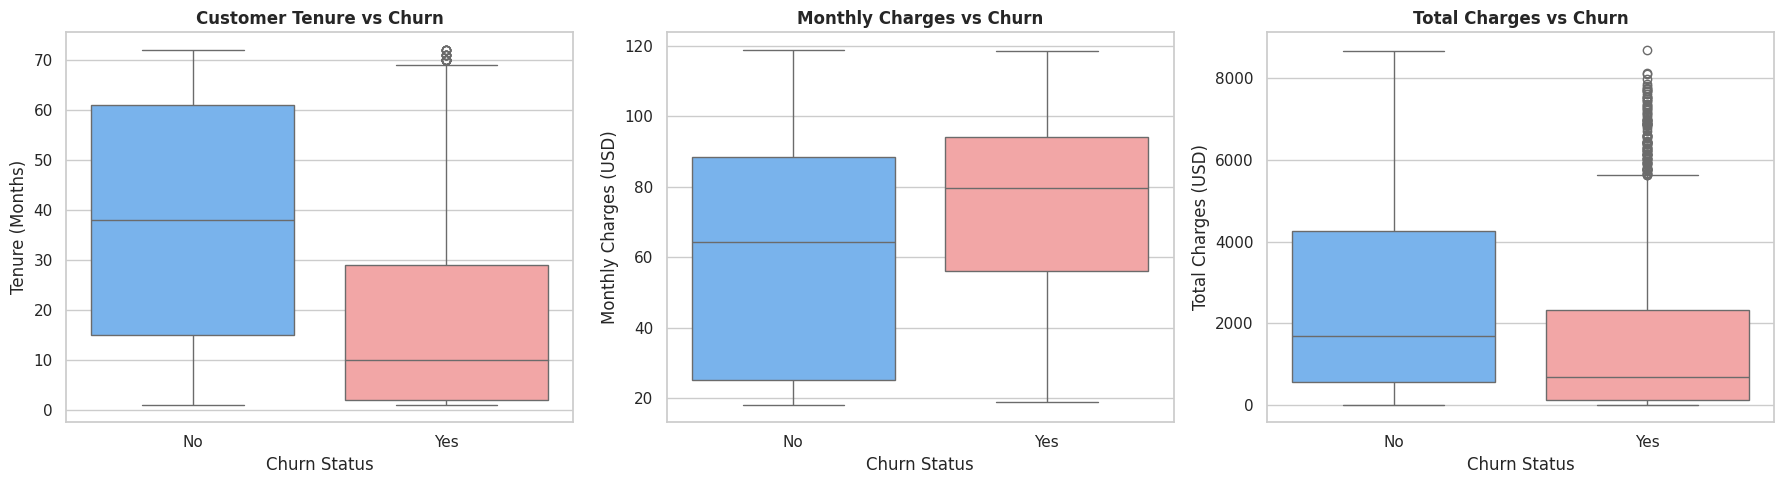

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
palette_churn = ["#66b3ff", "#ff9999"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(
    data=df_cleaned, x="Churn", y="tenure", palette=palette_churn, ax=axes[0]
)
axes[0].set_title(
    "Customer Tenure vs Churn", fontsize=12, fontweight="bold"
)
axes[0].set_xlabel("Churn Status")
axes[0].set_ylabel("Tenure (Months)")

sns.boxplot(
    data=df_cleaned,
    x="Churn",
    y="MonthlyCharges",
    palette=palette_churn,
    ax=axes[1],
)
axes[1].set_title(
    "Monthly Charges vs Churn", fontsize=12, fontweight="bold"
)
axes[1].set_xlabel("Churn Status")
axes[1].set_ylabel("Monthly Charges (USD)")

sns.boxplot(
    data=df_cleaned,
    x="Churn",
    y="TotalCharges",
    palette=palette_churn,
    ax=axes[2],
)
axes[2].set_title(
    "Total Charges vs Churn", fontsize=12, fontweight="bold"
)
axes[2].set_xlabel("Churn Status")
axes[2].set_ylabel("Total Charges (USD)")

plt.tight_layout()
plt.show()


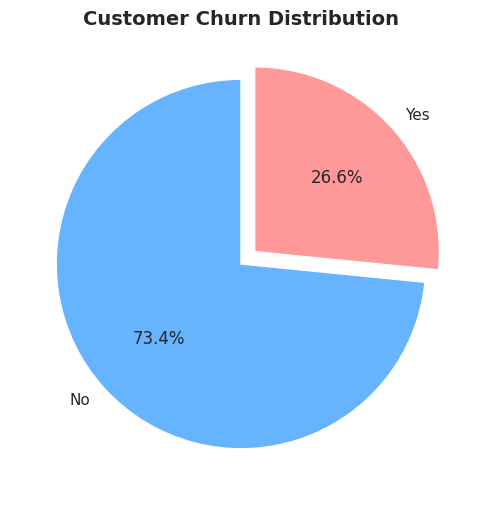

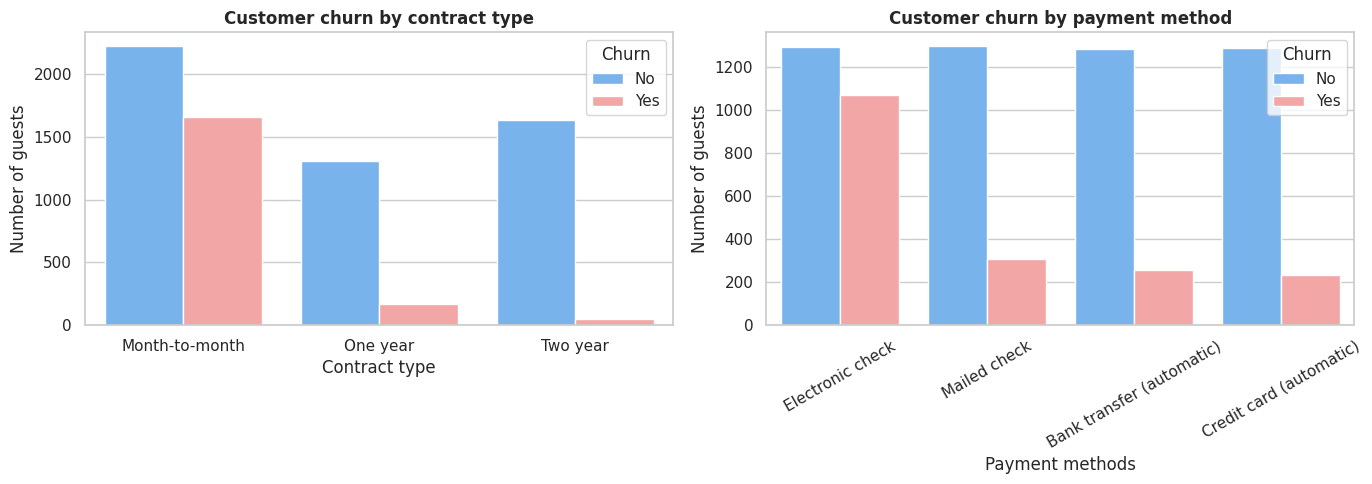

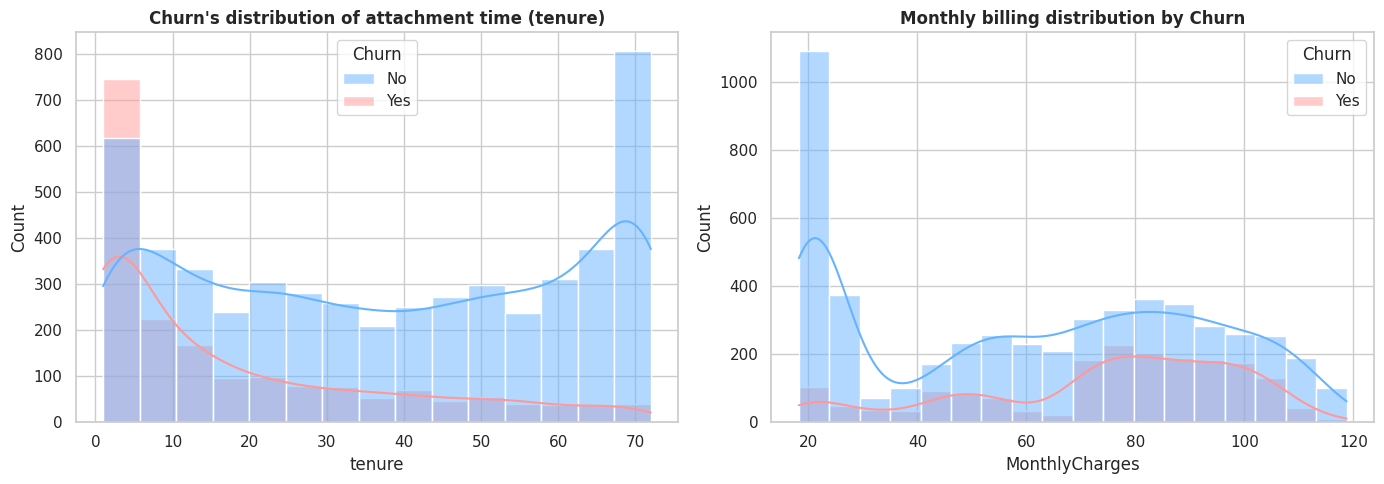

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

plt.figure(figsize=(6, 6))
churn_counts = df_cleaned['Churn'].value_counts()
plt.pie(churn_counts, labels=churn_counts.index, autopct='%1.1f%%',
        colors=['#66b3ff', '#ff9999'], startangle=90, explode=(0, 0.1))
plt.title("Customer Churn Distribution", fontsize=14, fontweight='bold')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df_cleaned, x='Contract', hue='Churn', palette=['#66b3ff', '#ff9999'], ax=axes[0])
axes[0].set_title("Customer churn by contract type", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Contract type")
axes[0].set_ylabel("Number of guests")

sns.countplot(data=df_cleaned, x='PaymentMethod', hue='Churn', palette=['#66b3ff', '#ff9999'], ax=axes[1])
axes[1].set_title("Customer churn by payment method", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Payment methods")
axes[1].set_ylabel("Number of guests")
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df_cleaned, x='tenure', hue='Churn', kde=True, palette=['#66b3ff', '#ff9999'], ax=axes[0])
axes[0].set_title("Churn's distribution of attachment time (tenure)", fontsize=12, fontweight='bold')

sns.histplot(data=df_cleaned, x='MonthlyCharges', hue='Churn', kde=True, palette=['#66b3ff', '#ff9999'], ax=axes[1])
axes[1].set_title("Monthly billing distribution by Churn", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()



Observations:
- Class imbalance: Only about 26–27% of customers churn, making "Accuracy" a potentially misleading metric; therefore, F1-score, Recall, and PR-AUC should be used as the primary evaluation metrics.
- Contract & Payment Method: Customers with month-to-month contracts and those paying via electronic check exhibit significantly higher churn rates compared to those with long-term contracts.
- Tenure & Monthly Charges: Churn is concentrated among customers with shorter tenure and higher monthly charges; these are key predictive variables..

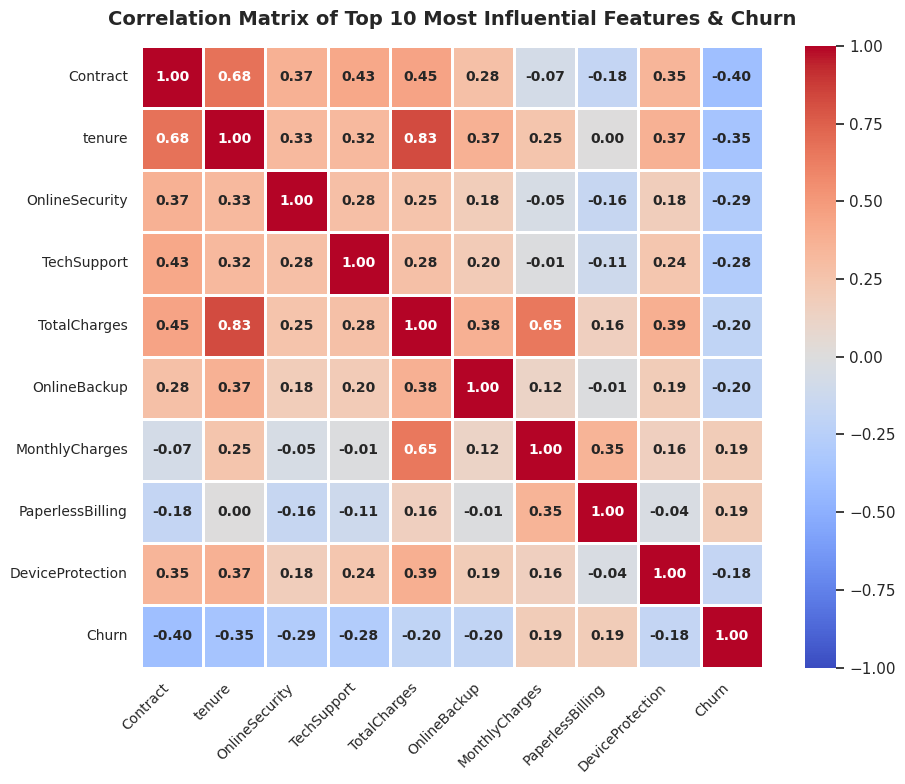

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

df_eda_temp = df_cleaned.copy()
for col in df_eda_temp.select_dtypes(include=['object']).columns:
    df_eda_temp[col] = df_eda_temp[col].astype('category').cat.codes

full_corr = df_eda_temp.astype(float).corr()

top_9_features = full_corr['Churn'].abs().sort_values(ascending=False).index[1:10].tolist()

top_10_cols = top_9_features + ['Churn']
corr_10x10 = full_corr.loc[top_10_cols, top_10_cols]

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_10x10,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    vmin=-1.0, vmax=1.0,
    linewidths=0.8,
    square=True,
    annot_kws={"size": 10, "weight": "bold"}
)

plt.title("Correlation Matrix of Top 10 Most Influential Features & Churn", fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.show()

Observtion:
- Contract và tenure có tương quan nghịch mạnh nhất với Churn; MonthlyCharges và PaperlessBilling tương quan thuận nhẹ.
- Lưu ý: các biến phân loại ở đây được mã hóa bằng category codes chỉ để khảo sát nhanh, nên hệ số tương quan chỉ mang tính tham khảo. Heatmap không dùng để chọn feature cho model.

In [ ]:
import pandas as pd

df_ml = df_cleaned.copy()
df_ml['Churn'] = df_ml['Churn'].map({'Yes': 1, 'No': 0})

cols_to_replace = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                   'TechSupport', 'StreamingTV', 'StreamingMovies']
for col in cols_to_replace:
    df_ml[col] = df_ml[col].replace('No internet service', 'No')
df_ml['MultipleLines'] = df_ml['MultipleLines'].replace('No phone service', 'No')

df_ml = pd.get_dummies(df_ml, drop_first=True)

bool_cols = df_ml.select_dtypes(include=['bool']).columns
df_ml[bool_cols] = df_ml[bool_cols].astype(int)

print(f"Dataset shape ready for split: {df_ml.shape}")
display(df_ml.head())


Dataset shape ready for split: (7032, 24)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_Yes,...,DeviceProtection_Yes,TechSupport_Yes,StreamingTV_Yes,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,0,1,0,0,0,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,0,1,0,0,1,0,...,1,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,1,0,0,1,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,0,1,0,0,0,0,...,1,1,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,1,0,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0


## 3. Machine Learning: Model Development and Evaluation

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, classification_report,
    ConfusionMatrixDisplay, f1_score, PrecisionRecallDisplay, precision_score,
    recall_score, RocCurveDisplay, roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate, train_test_split
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

SEED = 42
X = df_ml.drop(columns="Churn").copy()
y = df_ml["Churn"].astype(int).copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
preprocessor = ColumnTransformer(
    transformers=[('num', StandardScaler(), num_cols)],
    remainder='passthrough'
)

print(f"Customers: {len(df_ml):,} | Features: {X.shape[1]} | Churn rate: {y.mean():.1%}")
print(f"Training rows: {len(X_train):,} | Test rows: {len(X_test):,}")


Customers: 7,032 | Features: 23 | Churn rate: 26.6%
Training rows: 5,625 | Test rows: 1,407


In [ ]:
base_models = {
    "Dummy Baseline": DummyClassifier(strategy="stratified", random_state=SEED),
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=SEED),
    "Decision Tree": DecisionTreeClassifier(random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=120, random_state=SEED, n_jobs=1),
    "KNN": KNeighborsClassifier(n_neighbors=11),
    "AdaBoost": AdaBoostClassifier(n_estimators=100, random_state=SEED),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, random_state=SEED),
}

pipelines = {
    name: Pipeline([('prep', preprocessor), ('model', clf)])
    for name, clf in base_models.items()
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {
    "accuracy": "accuracy", "precision": "precision", "recall": "recall",
    "f1": "f1", "roc_auc": "roc_auc", "pr_auc": "average_precision",
}

cv_rows = []
for name, pipe in pipelines.items():
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    cv_rows.append({
        "Model": name,
        **{metric.upper(): scores[f"test_{metric}"].mean() for metric in scoring},
        "F1 std": scores["test_f1"].std(),
    })

cv_results = pd.DataFrame(cv_rows).sort_values("F1", ascending=False).reset_index(drop=True)
display(cv_results.round(3))


,Model,ACCURACY,PRECISION,RECALL,F1,ROC_AUC,PR_AUC,F1 std
0,Logistic Regression,0.803,0.655,0.546,0.595,0.846,0.660,0.023
1,AdaBoost,0.804,0.670,0.521,0.586,0.849,0.666,0.010
2,Gradient Boosting,0.801,0.662,0.511,0.576,0.848,0.664,0.016
3,KNN,0.782,0.597,0.553,0.574,0.818,0.572,0.025
4,Random Forest,0.793,0.645,0.496,0.561,0.827,0.631,0.015
5,Decision Tree,0.733,0.497,0.514,0.505,0.663,0.385,0.019
6,Dummy Baseline,0.608,0.265,0.268,0.266,0.499,0.266,0.020


In [ ]:
parameter_grids = {
    "Logistic Regression": {"model__C": [0.1, 0.5, 1.0, 2.0, 5.0], "model__class_weight": [None, "balanced"]},
    "Decision Tree": {"model__max_depth": [3, 5, 8, None], "model__min_samples_leaf": [5, 10, 20], "model__class_weight": [None, "balanced"]},
    "Random Forest": {"model__n_estimators": [100, 200], "model__max_depth": [None, 10, 20], "model__min_samples_leaf": [2, 5], "model__class_weight": [None, "balanced"]},
    "KNN": {"model__n_neighbors": [5, 11, 21, 31], "model__weights": ["uniform", "distance"], "model__p": [1, 2]},
    "AdaBoost": {"model__n_estimators": [50, 100, 150], "model__learning_rate": [0.1, 0.5, 1.0]},
    "Gradient Boosting": {"model__n_estimators": [80, 140, 200], "model__learning_rate": [0.03, 0.08, 0.15], "model__max_depth": [1, 2, 3]},
}

tuned_rows = []
best_estimators = {}

for name in parameter_grids.keys():
    search = GridSearchCV(
        pipelines[name], parameter_grids[name], scoring="f1", cv=cv,
        n_jobs=-1, refit=True
    )
    search.fit(X_train, y_train)
    best_estimators[name] = search.best_estimator_
    tuned_rows.append({
        "Model": name,
        "Best CV F1 (Tuned)": search.best_score_,
        "F1 std": search.cv_results_["std_test_score"][search.best_index_],
        "Best Params": search.best_params_
    })

tuned_df = pd.DataFrame(tuned_rows).sort_values("Best CV F1 (Tuned)", ascending=False).reset_index(drop=True)
pd.set_option("display.max_colwidth", None)
display(tuned_df.round(3))

best_name = tuned_df.loc[0, "Model"]
best_model = best_estimators[best_name]
print(f"-> Selected model: {best_name} | Best CV F1 (default threshold 0.50): {tuned_df.loc[0, 'Best CV F1 (Tuned)']:.3f}")

oof_probs = cross_val_predict(best_model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

thresholds = np.arange(0.20, 0.80, 0.01)
f1_scores = [f1_score(y_train, (oof_probs >= t).astype(int)) for t in thresholds]
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]
best_oof_f1 = f1_scores[best_idx]

print(f"-> Optimal Probability Threshold: {best_threshold:.2f} | OOF F1 after threshold tuning: {best_oof_f1:.3f}")


,Model,Best CV F1 (Tuned),F1 std,Best Params
0,Random Forest,0.636,0.006,"{'model__class_weight': 'balanced', 'model__max_depth': 10, 'model__min_samples_leaf': 5, 'model__n_estimators': 100}"
1,Logistic Regression,0.634,0.008,"{'model__C': 0.5, 'model__class_weight': 'balanced'}"
2,Decision Tree,0.607,0.009,"{'model__class_weight': 'balanced', 'model__max_depth': 5, 'model__min_samples_leaf': 10}"
3,KNN,0.598,0.015,"{'model__n_neighbors': 31, 'model__p': 1, 'model__weights': 'uniform'}"
4,Gradient Boosting,0.586,0.022,"{'model__learning_rate': 0.08, 'model__max_depth': 3, 'model__n_estimators': 200}"
5,AdaBoost,0.586,0.010,"{'model__learning_rate': 1.0, 'model__n_estimators': 100}"


-> Selected model: Random Forest | Best CV F1 (default threshold 0.50): 0.636
-> Optimal Probability Threshold: 0.46 | OOF F1 after threshold tuning: 0.639


,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,0.50 (Default),0.758,0.531,0.767,0.628,0.838,0.639
1,0.46 (Tuned),0.750,0.519,0.807,0.632,0.838,0.639



Classification Report (Tuned Threshold = 0.46):
              precision    recall  f1-score   support

        Stay      0.913     0.729     0.811      1033
       Churn      0.519     0.807     0.632       374

    accuracy                          0.750      1407
   macro avg      0.716     0.768     0.721      1407
weighted avg      0.808     0.750     0.763      1407



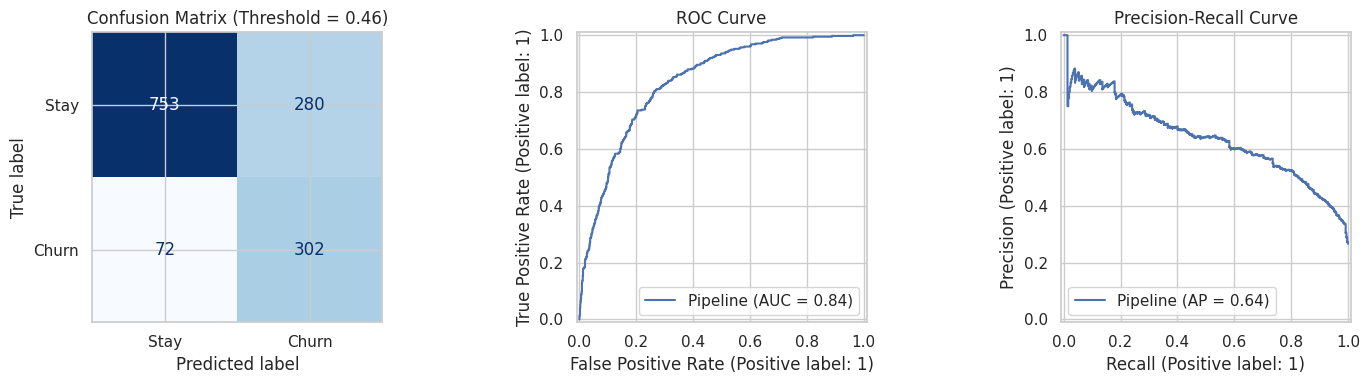

In [ ]:
y_probability = best_model.predict_proba(X_test)[:, 1]
y_pred_default = (y_probability >= 0.50).astype(int)
y_pred_tuned = (y_probability >= best_threshold).astype(int)

test_metrics = pd.DataFrame([
    {
        "Threshold": "0.50 (Default)",
        "Accuracy": accuracy_score(y_test, y_pred_default),
        "Precision": precision_score(y_test, y_pred_default, zero_division=0),
        "Recall": recall_score(y_test, y_pred_default, zero_division=0),
        "F1": f1_score(y_test, y_pred_default, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_probability),
        "PR-AUC": average_precision_score(y_test, y_probability),
    },
    {
        "Threshold": f"{best_threshold:.2f} (Tuned)",
        "Accuracy": accuracy_score(y_test, y_pred_tuned),
        "Precision": precision_score(y_test, y_pred_tuned, zero_division=0),
        "Recall": recall_score(y_test, y_pred_tuned, zero_division=0),
        "F1": f1_score(y_test, y_pred_tuned, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_probability),
        "PR-AUC": average_precision_score(y_test, y_probability),
    }
])
display(test_metrics.round(3))

print(f"\nClassification Report (Tuned Threshold = {best_threshold:.2f}):")
print(classification_report(y_test, y_pred_tuned, target_names=["Stay", "Churn"], digits=3, zero_division=0))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_tuned, display_labels=["Stay", "Churn"], cmap="Blues", ax=axes[0], colorbar=False
)
RocCurveDisplay.from_estimator(best_model, X_test, y_test, ax=axes[1])
PrecisionRecallDisplay.from_estimator(best_model, X_test, y_test, ax=axes[2])

axes[0].set_title(f"Confusion Matrix (Threshold = {best_threshold:.2f})")
axes[1].set_title("ROC Curve")
axes[2].set_title("Precision-Recall Curve")
plt.tight_layout()
plt.show()
